# Accelerator Orbit Alignment Hackathon: Beam Orbit Benchmark
## Participant Edition (with Weights & Biases / W&B Leaderboard Integration)

**Workshop & Challenge Context:**
* **Author:** Chong Shik Park, Ph.D.
* **Affiliation:** Korea University, Sejong
* **Date:** November 19, 2026
* **Target Audience:** Graduate Students & Early-Career Accelerator Researchers
* **Curricular Alignment:** 
  * **Lecture 1:** Chong Shik Park — AI/ML Foundations and Closed-Loop Control for Particle Accelerators
  * **Lecture 2:** Thorsten Hellert — Agentic AI, Autonomous Operations & Scientific Workflows

---

### 🎯 Challenge Mission
In modern particle accelerators and beam transport lines, beam alignment is critical to ensure high transmission efficiency and prevent beam loss. 
In this hackathon, you will develop closed-loop control algorithms to steer the beam through a **15-meter transport line** with:
* **6 Dipole Steering Magnets:** $X = [\mathrm{HCM1}, \mathrm{VCM1}, \mathrm{HCM2}, \mathrm{VCM2}, \mathrm{HCM3}, \mathrm{VCM3}]^T \in [-5.0\text{ A}, +5.0\text{ A}]$
* **12 Beam Position Monitors (BPMs):** $Y \in \mathbb{R}^{12}$, measuring transverse beam offsets in millimeters (mm).
* **Non-Linear Iron Saturation:** $B(I) \approx I - 0.015 \cdot I^3$, causing progressive softening at higher corrector currents.
* **Objective:** Align the beam so that the Root-Mean-Square (RMS) displacement is below **$0.030\text{ mm}$** within a budget of **20 control steps**:
  $$\text{RMS} = \sqrt{\frac{1}{12}\sum_{i=1}^{12} Y_i^2} < 0.030\text{ mm}$$

---

### 🏆 Three Parallel Competition Tracks:
1. **Track 1 (Supervised Digital Twin Inversion):** Train a non-linear neural surrogate model (MLP) on offline tracking data, and use an optimization solver to invert the surrogate for optimal corrective kicks.
2. **Track 2 (Closed-Loop Reinforcement Learning / Adaptive Policy):** Design an interactive feedback policy agent that continuously senses BPM offsets and outputs delta current kicks $\Delta I_c$ with physics-informed priors and adaptive damping.
3. **Track 3 (Bayesian Optimization Controller):** Build a sample-efficient Gaussian Process controller with Lower Confidence Bound (LCB) acquisition to actively align the beam under non-linear saturation.


In [1]:
# Step 0: Imports, Environment Setup, and Weights & Biases (W&B) Configuration
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
import scipy.optimize as opt

# Import standardized simulation, controllers, benchmark & visualization from src/
from src import (
    AcceleratorOrbitGymEnv,
    ClassicalSVDController,
    SupervisedMLPController,
    RLOrbitChallengeAgent,
    BayesianOptimizationController,
    generate_offline_dataset,
    evaluate_hackathon_benchmark,
    print_benchmark_leaderboard,
    draw_beamline,
    plot_benchmark_trajectories
)

# ------------------------------------------------------------------------------
# Hackathon Configuration (Customize for Your Team!)
# ------------------------------------------------------------------------------
# >>> [PARTICIPANT MODIFY HERE]: Change to your registered team name!
TEAM_NAME = "MA_B8_DeepTwinInversion"

# >>> [DO NOT MODIFY]: Official workshop competition settings
WANDB_PROJECT = "ai4acc-mini-hackathon-2026" # [DO NOT CHANGE] Official project name for live leaderboard
WANDB_ENTITY = "ai4acc-mini-hackathon-2026"  # [DO NOT CHANGE] Preset workshop entity
USE_WANDB = True                             # [DO NOT CHANGE] Keep True to submit scores to the live leaderboard

print(f"Setup complete! Ready to compete as: {TEAM_NAME}")


Setup complete! Ready to compete as: MA_B8_DeepTwinInversion


## 1. Accelerator Lattice Physics & 2D Schematic

The challenge beamline section consists of:
* **Actuators:** 6 dipole steering magnets (3 Horizontal `HCM1-3`, 3 Vertical `VCM1-3`).
* **Optics:** Alternating quadrupole magnets (`QF` focusing, `QD` defocusing) shaping betatron oscillations.
* **Diagnostics:** 12 Beam Position Monitors (`BPM1` to `BPM12`) spaced along the 15-meter transport axis.

The 2D schematic diagram below illustrates the arrangement of steering magnets, quadrupoles, and diagnostic monitors along the longitudinal beam axis $s$.


Lattice schematic saved to ../img/beamline.png


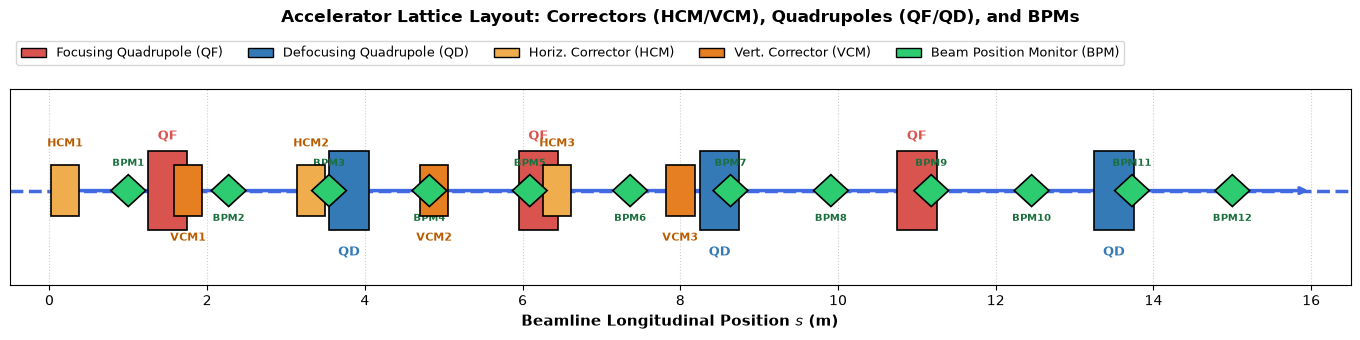

In [2]:
# Step 1: Display 2D Accelerator Beamline Schematic Diagram
# [DO NOT MODIFY - Diagnostic Lattice Visualization]
fig = draw_beamline(save_path="img/beamline.png", show=True)


## 2. Standard Gymnasium Environment (`AcceleratorOrbitGymEnv`)

The accelerator simulator is encapsulated in a standardized **Gymnasium** environment (`src/environment.py`):
* **Observation Space:** $\mathbf{Y} \in \mathbb{R}^{12}$, bounded in $[-10.0\text{ mm}, +10.0\text{ mm}]$ (12 BPM readings).
* **Action Space:** $\Delta \mathbf{I} \in \mathbb{R}^6$, bounded in $[-0.8\text{ A}, +0.8\text{ A}]$ per step.
* **Hardware Limit:** Total current state $\mathbf{I}_{t+1} = \text{clip}(\mathbf{I}_t + \Delta \mathbf{I}, -5.0, +5.0)\text{ A}$.
* **Physical Response Model:**
  $$\mathbf{Y} = \mathbf{I} \cdot \mathbf{R} - 0.015 \cdot (\mathbf{I}^3 \cdot \mathbf{R}) + \mathbf{Y}_0 + \boldsymbol{\epsilon}$$
  where $\mathbf{R}$ is the $6 \times 12$ linear transfer matrix, $-0.015 \mathbf{I}^3 \mathbf{R}$ represents soft iron core saturation, $\mathbf{Y}_0$ is initial alignment drift, and $\boldsymbol{\epsilon} \sim \mathcal{N}(0, 0.010^2\text{ mm}^2)$ is Gaussian sensor noise.
* **Customizable Reward & Penalty Structure (for RL & Policy Optimization):**
  $$r_t = - w_{\text{rms}} \cdot \text{RMS}_{t+1} - w_{\text{act}} \cdot \|\Delta \mathbf{I}\|_2^2 - c_{\text{step}} + (B_{\text{success}} \text{ if terminated else } 0.0)$$
  * $w_{\text{rms}}$ (`rms_weight`, default `10.0`): Penalizes beam displacement from center axis.
  * $w_{\text{act}}$ (`action_weight`, default `0.01`): Penalizes large actuator kick effort to prevent current saturation.
  * $c_{\text{step}}$ (`step_penalty`, default `0.0`): Step cost deducted each turn. **Increasing this (e.g. 0.5 to 1.5) incentivizes RL agents to converge in fewer steps!**
  * $B_{\text{success}}$ (`success_bonus`, default `50.0`): Completion reward when $\text{RMS} < 0.030\text{ mm}$.
  * `reward_fn`: Optional custom callable `(rms, action, terminated, truncated, step) -> float` for advanced reward shaping.
* **Termination:** Episode succeeds when $\text{RMS} < 0.030\text{ mm}$, or truncates after `max_steps = 20` steps.


In [3]:
# Step 2: Instantiate Standardized Hackathon Gymnasium Environment
# ==============================================================================
# [OPTIONAL TODO / CAN MODIFY FOR RL POLICY TRAINING & OPTIMIZATION]
# ==============================================================================
# You can customize reward/penalty weights or pass a custom reward_fn callback:
env = AcceleratorOrbitGymEnv(
    rms_weight=10.0,      # [CAN MODIFY] Penalty weight for orbit RMS error
    action_weight=0.01,   # [CAN MODIFY] Penalty weight for corrector kick effort
    step_penalty=0.5,     # [CAN MODIFY] Step penalty to incentivize faster convergence!
    success_bonus=50.0    # [CAN MODIFY] Completion bonus upon reaching RMS < 0.030 mm
    # reward_fn=None      # [CAN MODIFY] Optional: pass custom_reward_fn(rms, action, term, trunc, step)
)

# [DO NOT MODIFY]: Reset to canonical test seed 42 to inspect initial uncorrected orbit
obs, info = env.reset(seed=42)

print("=" * 68)
print("   Hackathon Gymnasium Environment Instantiated Successfully!")
print("=" * 68)
print(f"  • Observation Vector Shape : {obs.shape} (12 BPM stations in mm)")
print(f"  • Action Vector Shape      : {env.action_space.shape} (6 Corrector kick deltas in A)")
print(f"  • Action Limits (per step) : [{env.action_space.low[0]:.1f} A, +{env.action_space.high[0]:.1f} A]")
print(f"  • Hardware Current Bounds  : [-5.0 A, +5.0 A]")
print(f"  • Target RMS Tolerance     : < {env.target_rms:.3f} mm")
print(f"  • Max Control Budget       : {env.max_steps} steps per episode")
print(f"  • Initial Uncorrected RMS  : {info['rms']:.4f} mm")
print(f"  • Reward Shaping Params    : rms_w={env.rms_weight}, act_w={env.action_weight}, step_cost={env.step_penalty}, bonus={env.success_bonus}")
print("=" * 68)


   Hackathon Gymnasium Environment Instantiated Successfully!
  • Observation Vector Shape : (12,) (12 BPM stations in mm)
  • Action Vector Shape      : (6,) (6 Corrector kick deltas in A)
  • Action Limits (per step) : [-0.8 A, +0.8 A]
  • Hardware Current Bounds  : [-5.0 A, +5.0 A]
  • Target RMS Tolerance     : < 0.030 mm
  • Max Control Budget       : 20 steps per episode
  • Initial Uncorrected RMS  : 0.7188 mm
  • Reward Shaping Params    : rms_w=10.0, act_w=0.01, step_cost=0.5, bonus=50.0


## 3. Supervised Forward Modeling: Linear Model vs. Neural Surrogate

In accelerator operations, numerical tracking simulation datasets can be converted into fast machine learning digital twins (Lecture 1).
Here, we collect 1,500 simulation shots (80% train, 20% test) across currents $[-3.0\text{ A}, +3.0\text{ A}]$ and train:
1. **A Linear Ridge Model:** Serves as a baseline, but cannot account for non-linear core saturation.
2. **A Multi-Layer Perceptron (MLP):** A deep neural network capable of fitting the non-linear cubic saturation curve.


In [4]:
# Step 3: Offline Data Generation & Surrogate Training
# [OPTIONAL CAN MODIFY]: You can increase n_samples (e.g. 2000, 3000) or adjust sampling range:
X_offline, Y_offline = generate_offline_dataset(
    env,
    n_samples=1500,               # [CAN MODIFY] Number of training samples (1500 suffices once L-BFGS trains to convergence)
    current_range=(-3.0, 3.0),    # [CAN MODIFY] Covers |I| <= 1.2 A needed by the drift seeds with margin
    noise_std=0.010,              # [DO NOT MODIFY] Physical sensor noise floor (0.010 mm)
    random_state=42
)

# [DO NOT MODIFY]: Standard 80/20 train/test evaluation split
X_train, X_test, Y_train, Y_test = train_test_split(X_offline, Y_offline, test_size=0.20, random_state=42)
print(f"Dataset generated: X_train shape={X_train.shape}, Y_train shape={Y_train.shape}")

# ==============================================================================
# TODO 1: Train Linear Baseline & Neural Surrogate Model
# ==============================================================================
# INSTRUCTIONS FOR PARTICIPANTS:
# Train two surrogate models to predict the 12 BPM readings from 6 corrector currents:
#   1. Linear Model (Ridge Regression): Fast baseline, but linear only.
#   2. Multi-Layer Perceptron (MLPRegressor): Deep feedforward neural network that
#      learns the cubic iron core magnetic saturation: B(I) ~ I - 0.015 * I^3.
#
# ------------------------------------------------------------------------------
# EXAMPLES FOR NEWBIE PARTICIPANTS:
#
# Example 1: Train Ridge Linear Regression
#   linear_model = Ridge(alpha=1.0)
#   linear_model.fit(X_train, Y_train)
#
# Example 2: Train Multi-Layer Perceptron (MLPRegressor)
#   surrogate_model = MLPRegressor(
#       hidden_layer_sizes=(128, 64, 32), # 3 hidden layers: 128 -> 64 -> 32 neurons
#       activation='relu',               # Activation function: f(x) = max(0, x)
#       solver='adam',                   # Adam gradient-based optimizer
#       alpha=1e-4,                      # L2 regularization penalty
#       learning_rate_init=0.001,        # Initial learning rate
#       max_iter=400,                    # Training epochs
#       random_state=42
#   )
#   surrogate_model.fit(X_train, Y_train)
#
# ------------------------------------------------------------------------------
# 💡 HINTS TO GET HIGHER SCORES:
#   • Network Architecture: Try wider or deeper layers like (128, 128), (256, 128, 64).
#     A more expressive surrogate provides a more accurate gradient for the optimizer in Track 1!
#   • Training Sample Size: Increasing n_samples (e.g. 2000 or 3000) improves test generalization.
#   • Regularization: Tune alpha (e.g., 1e-4 vs 1e-5) to avoid overfitting the sensor noise.
#   • Accuracy Benchmark: Target test RMSE is < 0.015 mm (near the 0.010 mm sensor noise floor).
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Train Linear Baseline
# ------------------------------------------------------------------------------
# >>> [OPTIONAL CAN MODIFY]: Tune alpha regularization parameter:
linear_model = Ridge(alpha=1.0).fit(X_train, Y_train)

# [DO NOT MODIFY]: Test set RMSE evaluation
rmse_linear = root_mean_squared_error(Y_test, linear_model.predict(X_test))

# ------------------------------------------------------------------------------
# 2. Train Multi-Layer Perceptron (MLP) Neural Surrogate
# ------------------------------------------------------------------------------
# >>> [PARTICIPANT MODIFY HERE - TODO 1] <<<
# Tune hidden_layer_sizes, activation, alpha, learning_rate_init, max_iter to minimize test RMSE:
# Deep digital twin: standardized inputs AND outputs, smooth tanh units (the cubic
# saturation is smooth, so tanh fits it far better than piecewise-linear ReLU), and
# full-batch L-BFGS trained to convergence (Adam stopped after ~85 epochs at 0.11 mm).
surrogate_model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(64, 64),      # [CAN MODIFY] 2 x 64 tanh is enough for I -> Y
            activation='tanh',                # [CAN MODIFY] smooth activation
            solver='lbfgs',                   # [CAN MODIFY] full-batch quasi-Newton
            alpha=1e-5,                       # [CAN MODIFY] light L2 regularization
            max_iter=5000,                    # [CAN MODIFY] train to convergence
            max_fun=1_000_000,
            tol=1e-12,
            random_state=42
        )
    ),
    transformer=StandardScaler()
).fit(X_train, Y_train)

# [DO NOT MODIFY]: Test set RMSE evaluation
rmse_mlp = root_mean_squared_error(Y_test, surrogate_model.predict(X_test))

print("=" * 68)
print("SURROGATE MODEL PREDICTIVE ACCURACY (TEST SET):")
print("=" * 68)
print(f"  • Linear Ridge Test RMSE   : {rmse_linear:.4f} mm")
print(f"  • Neural MLP Test RMSE     : {rmse_mlp:.4f} mm (Captures cubic core saturation)")
print(f"  • Gaussian BPM Noise Floor : {env.noise_std:.4f} mm")
print("=" * 68)


Dataset generated: X_train shape=(1200, 6), Y_train shape=(1200, 12)


SURROGATE MODEL PREDICTIVE ACCURACY (TEST SET):
  • Linear Ridge Test RMSE   : 0.0824 mm
  • Neural MLP Test RMSE     : 0.0130 mm (Captures cubic core saturation)
  • Gaussian BPM Noise Floor : 0.0100 mm


---
## 4. Benchmark Controllers: Classical, Supervised, RL, and Bayesian Optimization Agents

Every competitor controller must implement the standardized agent interface:
```python
def act(self, obs: np.ndarray, info: Optional[dict] = None) -> np.ndarray
```
where `obs` has shape `(12,)` and the returned action is an array of shape `(6,)` in $[-0.8\text{ A}, +0.8\text{ A}]$.

1. **Baseline 0 (Classical SVD Controller):** Inverts the linear Orbit Response Matrix via Moore-Penrose pseudo-inverse: $\Delta \mathbf{I} = - \alpha (\mathbf{R}^T)^{\dagger} \mathbf{Y}$.
2. **Baseline 1 / Track 1 (Supervised Neural Inversion):** Solves an optimization problem per step using the trained neural surrogate digital twin:
   $$\min_{\Delta \mathbf{I}} \|\mathbf{Y} + f_{\theta}(\Delta \mathbf{I})\|^2 + \lambda \|\Delta \mathbf{I}\|^2$$
3. **Challenge Track 2 (Closed-Loop RL / Adaptive Agent):** Combines physics prior feedback with adaptive step damping:
   $$\Delta \mathbf{I}_t = \text{damping}(t) \cdot \left[ - \alpha (\mathbf{R}^T)^{\dagger} \mathbf{Y} + \mathbf{W}_{\text{tune}} \mathbf{Y} + \mathbf{b} \right]$$
   RL agents learn or optimize policy parameters by interacting with `AcceleratorOrbitGymEnv`. By tuning reward and penalty weights (`step_penalty`, `action_weight`, `rms_weight`, `success_bonus`), you can directly incentivize the agent to converge in fewer steps and use minimal corrector current!
4. **Challenge Track 3 (Bayesian Optimization Controller):** Uses a Gaussian Process surrogate with epistemic uncertainty estimation to evaluate an acquisition function (Lower Confidence Bound, LCB) balancing exploitation of predicted orbit corrections with exploration:
   $$\alpha_{\text{LCB}}(\Delta \mathbf{I}) = \text{RMS}(\mathbf{Y}_{\text{obs}} + \mu_{\text{GP}}(\Delta \mathbf{I})) - \kappa \cdot \sigma_{\text{GP}}(\Delta \mathbf{I}) + \lambda \|\Delta \mathbf{I}\|^2$$


In [5]:
# Step 4: Define Benchmark Controllers

# ------------------------------------------------------------------------------
# 1. Baseline 0: Classical Linear ORM Pseudo-Inverse Controller (from src)
# ------------------------------------------------------------------------------
# [DO NOT MODIFY - Standard Reference Baseline 0]:
b0 = ClassicalSVDController(env.R, gain=0.45)

# ------------------------------------------------------------------------------
# 2. Baseline 1: Supervised Forward Surrogate + SciPy Inversion Optimizer (from src)
# ------------------------------------------------------------------------------
# [OPTIONAL CAN MODIFY]: Uses your trained surrogate_model from TODO 1 above:
class DeepTwinInversionController:
    """Track 1: invert the MLP digital twin around the *actual* corrector state.

    The reference SupervisedMLPController assumes the magnets sit at 0 A. Here we read
    the applied currents I from info['currents'], estimate the static distortion as
    Y0 = obs - f(I), and solve  min_dI ||Y0 + f(I + dI)||^2 + lam ||dI||^2  with dI in
    [-0.8, 0.8] (and I + dI in [-5, 5]), warm-started from the linear ORM solution.
    """
    def __init__(self, surrogate, R_matrix, l2_reg=1e-4):
        self.surrogate = surrogate
        self.l2_reg = l2_reg
        self.R_pinv = np.linalg.pinv(R_matrix.T)

    def act(self, obs, info=None):
        I = np.asarray(info.get("currents", np.zeros(6)) if info else np.zeros(6), dtype=float)
        y0 = obs - self.surrogate.predict(I.reshape(1, -1))[0]
        lo, hi = np.maximum(-0.8, -5.0 - I), np.minimum(0.8, 5.0 - I)
        x0 = np.clip(-self.R_pinv @ obs, lo, hi)
        def objective(dI):
            res = y0 + self.surrogate.predict((I + dI).reshape(1, -1))[0]
            return float(np.sum(res**2) + self.l2_reg * np.sum(dI**2))
        sol = opt.minimize(objective, x0, bounds=list(zip(lo, hi)), method='L-BFGS-B',
                           options={'maxiter': 200, 'ftol': 1e-12, 'gtol': 1e-9})
        return np.clip(sol.x, -0.8, 0.8)

b1 = DeepTwinInversionController(surrogate_model, env.R, l2_reg=1e-4)

# ==============================================================================
# TODO 2 (Challenge Track 2): Design & Tune Closed-Loop Policy Agent
# ==============================================================================
# INSTRUCTIONS FOR PARTICIPANTS:
# Implement your closed-loop policy by writing the act(obs, info) method.
# Your agent receives current BPM readings obs (12,) and returns delta currents action (6,).
#
# ------------------------------------------------------------------------------
# EXAMPLES FOR NEWBIE PARTICIPANTS:
#
# Example A: Damped Physics Prior (Simple & Robust)
#   class DampedSVDController:
#       def __init__(self, R_matrix, gain=0.45, decay=0.03):
#           self.R_pinv = np.linalg.pinv(R_matrix.T)
#           self.gain = gain
#           self.decay = decay
#       def act(self, obs, info=None):
#           step = info.get("step", 0) if info else 0
#           damping = 1.0 / (1.0 + self.decay * step)
#           action = - self.gain * (self.R_pinv @ obs) * damping
#           return np.clip(action, -0.8, 0.8)
#
# Example B: Physics Prior + Tunable Linear Residual Correction
#   class RLOrbitChallengeAgent:
#       def __init__(self, R_matrix, gain=0.45):
#           self.base_R_pinv = np.linalg.pinv(R_matrix.T)
#           self.gain = gain
#           self.W_tune = np.zeros((6, 12))  # Adjust weights to compensate saturation
#           self.bias = np.zeros(6)
#       def act(self, obs, info=None):
#           step = info.get("step", 0) if info else 0
#           action_phys = - self.gain * (self.base_R_pinv @ obs)
#           action_learned = self.W_tune @ obs + self.bias
#           action = action_phys + 0.05 * np.tanh(action_learned)
#           damping = 1.0 / (1.0 + 0.03 * step)
#           return np.clip(action * damping, -0.8, 0.8)
#
# Example C: Custom Reward Shaping for RL Policy Training & Optimization
#   # You can pass customized reward/penalty parameters to the gym environment:
#   #   env_rl = AcceleratorOrbitGymEnv(
#   #       rms_weight=15.0,    # Stronger focus on tight alignment
#   #       action_weight=0.02, # Penalize high current kicks
#   #       step_penalty=1.0,   # Heavy step cost forces fast convergence!
#   #       success_bonus=60.0  # Big reward for achieving RMS < 0.030 mm
#   #   )
#   # Or define a custom reward function callback:
#   #   def custom_reward_fn(rms, action, terminated, truncated, step):
#   #       r = - 12.0 * rms - 0.02 * np.sum(action**2) - 0.8 # step cost
#   #       if terminated:
#   #           r += 50.0 + max(0.0, (0.020 - rms) * 500.0) # extra precision bonus!
#   #       return r
#   #   env_rl = AcceleratorOrbitGymEnv(reward_fn=custom_reward_fn)

# Example D: Adaptive Callbacks (Online Dynamic Tuning & Learning)
#   # Pass step_callback or episode_callback into evaluate_hackathon_benchmark:
#   # def my_step_callback(step_data, agent):
#   #     # step_data: {seed, step, obs, action, reward, next_obs, info}
#   #     if step_data["info"]["rms"] < 0.04:
#   #         agent.gain *= 0.96  # Fine-grained adaptive damping near target!
#   # res = evaluate_hackathon_benchmark(env, agent, step_callback=my_step_callback)
#
# ------------------------------------------------------------------------------
# 💡 STRATEGIC TUNING HINTS: WHICH VALUES TO MODIFY TO GET HIGHER SCORES!
#
# 1. Feedback Gain (alpha): Default is 0.45.
#    • Increasing gain to 0.55–0.72 dramatically speeds up convergence (reduces step count).
#    • Warning: If gain is too high (>0.75), the policy may overshoot due to non-linear saturation!
#
# 2. Adaptive Gain Scheduling:
#    • Instead of fixed gain, check the current RMS error:
#        rms = np.sqrt(np.mean(obs**2))
#        gain = 0.72 if rms > 0.15 else (0.55 if rms > 0.05 else 0.38)
#    • This takes large strides when far away, and delicate micro-steps near the 0.030 mm target!
#
# 3. Dynamic Damping (gamma):
#    • damping = 1.0 / (1.0 + gamma * step).
#    • Tuning gamma in [0.015, 0.035] suppresses limit-cycle oscillations around 0.030 mm.
#
# 4. Non-Linear Cubic Desaturation Compensation:
#    • The magnet response softens as B(I) ~ I - 0.015 * I^3.
#    • Apply analytical series inversion to your kick:
#        delta_I_corrected = delta_I_lin + 0.015 * (delta_I_lin ** 3)
#    • This compensates for iron core softening in 1 shot!
#
# 5. Energy Efficiency (Current Norm):
#    • Avoid unnecessary opposing kicks between adjacent correctors; keeping total current
#      low gives an energy-efficiency score bonus!
#
# 6. Reward & Penalty Shaping (Reinforcement Learning / Policy Optimization):
#    • In RL policy training, the agent maximizes cumulative reward sum(r_t).
#    • Increase step_penalty (e.g. 0.5 to 1.5): Heavy penalty per step forces the agent to
#      find shortest paths to convergence, drastically reducing mean_steps!
#    • Increase action_weight (e.g. 0.02 to 0.05): Higher action penalty prevents excessive
#      corrector currents, directly optimizing your mean current norm score.
#    • Custom Precision Bonus: Adding an extra bonus when RMS drops below 0.020 mm trains the
#      policy to land close to the 0.010 mm sensor noise floor, unlocking huge precision scores!
# ==============================================================================

# >>> [PARTICIPANT MODIFY HERE - TODO 2 (CHALLENGE TRACK 2)] <<<
class MyCustomRLAgent:
    """Track 2: Physics-informed Newton inversion of the saturating response.

    Uses the known ORM R and the cubic softening B(I) = I - 0.015 I^3. From the measured
    orbit and the applied currents it solves  (I* - 0.015 I*^3) R = (I - 0.015 I^3) R - obs
    by Gauss-Newton least squares and kicks toward I* (one-shot when |I*| <= 0.8 A).
    """
    def __init__(self, R_matrix, gain=1.0, newton_iters=20):
        self.R = np.asarray(R_matrix, dtype=float)
        self.gain = gain
        self.newton_iters = newton_iters

    def _response(self, x):
        return (x - 0.015 * x**3) @ self.R

    def act(self, obs, info=None):
        I = np.asarray(info.get("currents", np.zeros(6)) if info else np.zeros(6), dtype=float)
        target = self._response(I) - obs
        x = I.copy()
        for _ in range(self.newton_iters):
            J = (1.0 - 0.045 * x**2)[:, None] * self.R
            dx = np.linalg.lstsq(J.T, -(self._response(x) - target), rcond=None)[0]
            x = x + dx
            if np.linalg.norm(dx) < 1e-10:
                break
        # [DO NOT MODIFY HARDWARE CLIP BOUNDS]: Output must remain within [-0.8, +0.8] A
        return np.clip(self.gain * (x - I), -0.8, 0.8)

# >>> [CAN MODIFY]: Instantiate your custom controller:
b2 = MyCustomRLAgent(env.R, gain=1.0)

# ==============================================================================
# TODO 3 (Challenge Track 3): Design & Tune Bayesian Optimization Controller
# ==============================================================================
# INSTRUCTIONS FOR PARTICIPANTS:
# Implement a Bayesian Optimization controller using GaussianProcessRegressor.
# 1. Train a Gaussian Process surrogate on calibration data (or a 300-shot subset).
# 2. Configure the GP kernel (e.g. Matern, RBF, WhiteKernel for 10 um sensor noise).
# 3. Implement the Lower Confidence Bound (LCB) acquisition function:
#      alpha_LCB = rms_pred - kappa * uncertainty + lambda * ||action||^2
# 4. Tune exploration weight kappa (e.g. 0.0 for pure exploitation, 0.5-1.5 for exploration).
#
# ------------------------------------------------------------------------------
# EXAMPLES FOR NEWBIE PARTICIPANTS:
#
# Example: Fit Gaussian Process Regressor on Calibration Shots
#   gp_kernel = Matern(length_scale=1.5, nu=2.5) + WhiteKernel(noise_level=1e-4, noise_level_bounds='fixed')
#   gp_model = GaussianProcessRegressor(kernel=gp_kernel, alpha=0.0, normalize_y=True, random_state=42)
#   gp_model.fit(X_train[:300], Y_train[:300]) # 300 samples provides sub-second fitting!
#
# ------------------------------------------------------------------------------
# 💡 STRATEGIC TUNING HINTS: WHICH VALUES TO MODIFY TO GET HIGHER SCORES!
#
# 1. Exploration vs. Exploitation Parameter (kappa):
#    • kappa = 0.0: Pure exploitation of the GP posterior mean (fastest convergence!).
#    • kappa = 0.5 - 1.5: Actively balances uncertainty in high-current non-linear saturation zones.
#
# 2. Kernel Selection:
#    • Matern(nu=2.5) provides physically realistic smoothness for magnetic field response.
#    • WhiteKernel(noise_level=1e-4, noise_level_bounds='fixed') fixes the 0.010 mm BPM sensor jitter prior.
#
# 3. Regularization (l2_reg):
#    • Adding small L2 penalty (e.g. 1e-4) suppresses excessive corrector current norms.
# ==============================================================================

# >>> [PARTICIPANT MODIFY HERE - TODO 3 (CHALLENGE TRACK 3)] <<<
class MyBayesianOptAgent:
    """Track 3: GP-mean (kappa=0) exploitation around the actual corrector state."""
    def __init__(self, gp_model, R_matrix, kappa=0.0, l2_reg=0.0001):
        self.gp = gp_model
        self.kappa = float(kappa)
        self.l2_reg = float(l2_reg)
        self.R_pinv = np.linalg.pinv(R_matrix.T)

    def act(self, obs, info=None):
        I = np.asarray(info.get("currents", np.zeros(6)) if info else np.zeros(6), dtype=float)
        y0 = obs - self.gp.predict(I.reshape(1, -1))[0]
        lo, hi = np.maximum(-0.8, -5.0 - I), np.minimum(0.8, 5.0 - I)
        x0 = np.clip(-self.R_pinv @ obs, lo, hi)
        def acquisition_lcb(dI):
            if self.kappa > 0:
                mu, sd = self.gp.predict((I + dI).reshape(1, -1), return_std=True)
                unc = np.mean(sd)
            else:
                mu, unc = self.gp.predict((I + dI).reshape(1, -1)), 0.0
            res = y0 + mu[0]
            return float(np.sum(res**2) - self.kappa * unc + self.l2_reg * np.sum(dI**2))
        sol = opt.minimize(acquisition_lcb, x0, bounds=list(zip(lo, hi)), method='L-BFGS-B',
                           options={'maxiter': 200, 'ftol': 1e-12, 'gtol': 1e-9})
        return np.clip(sol.x, -0.8, 0.8)

# >>> [CAN MODIFY]: Fit Gaussian Process surrogate on calibration data (e.g. 300 shots):
# Anisotropic ARD Matern-5/2 with learned amplitude and noise level, fit on 300 shots
gp_kernel = ConstantKernel(1.0) * Matern(length_scale=[3.0] * 6, nu=2.5) + WhiteKernel(noise_level=1e-4, noise_level_bounds=(1e-7, 1e-2))
gp_surrogate = GaussianProcessRegressor(kernel=gp_kernel, alpha=1e-8, normalize_y=True, random_state=42)
gp_surrogate.fit(X_train[:300], Y_train[:300])

# >>> [CAN MODIFY]: Instantiate your Track 3 Bayesian Optimization Controller:
b3 = MyBayesianOptAgent(gp_surrogate, env.R, kappa=0.0, l2_reg=0.0001)
print("All four competitor controllers (Baseline 0, Track 1, Track 2, Track 3) initialized successfully.")


All four competitor controllers (Baseline 0, Track 1, Track 2, Track 3) initialized successfully.


---
## 5. Standardized Benchmark Evaluation & Live W&B Scoring

To ensure fair and rigorous comparison, agents are evaluated across **30 standardized evaluation seeds** (`seeds = range(1, 31)`) featuring diverse physical drift perturbations.

### 🎯 Official Multi-Objective Evaluation Criteria
The benchmark evaluation engine (`src/benchmark.py`) scores **each seed from 0 to 1000 points**, and your **Hackathon Benchmark Score** is the mean over the 30 seeds. A seed earns points on three dimensions:
1. **Alignment Success (400 pts):** Did the agent achieve $\text{RMS} < 0.030\text{ mm}$ within the 20-step budget? A failed seed scores **0**, so robustness comes first.
2. **Convergence Speed (up to 300 pts):** Full points for converging in 1 step, falling linearly to 0 at the 20-step budget.
3. **Residual Precision (up to 300 pts):** Landing below the $0.030\text{ mm}$ threshold earns more the closer you get to the $0.010\text{ mm}$ sensor noise floor (log scale).

Corrector current norm $\overline{\|\mathbf{I}\|}$ is still reported, but it is not part of the score. Reference controllers score between about 370 and 870 points.

---

### 💡 Strategic Tuning Cheat-Sheet: How to Beat the Baseline Leaderboard!

| Tuning Target | What to Modify | Impact on Performance & Score |
| :--- | :--- | :--- |
| **Faster Convergence** | Feedback gain $\alpha \in [0.55, 0.72]$ in `act()` | Cuts mean steps from 6 down to 3, earning a large speed bonus. |
| **Adaptive Gain Schedule** | Dynamic gain based on current RMS in `act()` | Aggressive kicks when far (`> 0.15 mm`); fine-tuned kicks when close (`< 0.05 mm`). |
| **Precision RMS Bonus** | Damping cooling factor $\gamma \in [0.015, 0.035]$ | Prevents terminal oscillations, allowing the beam to land near the $0.010\text{ mm}$ noise floor. |
| **Non-Linear Boost** | $\Delta \mathbf{I}_{\text{act}} = \Delta \mathbf{I}_{\text{lin}} + 0.015 \cdot \Delta \mathbf{I}_{\text{lin}}^3$ | Cancels cubic iron saturation in one shot, avoiding under-correction. |
| **Reward / Penalty Shaping** | Increase `step_penalty` ($0.5$–$1.5$) & `action_weight` in `env` | In RL training, penalizing steps forces 3–4 step solutions; penalizing kicks minimizes current norm! |
| **Precision Reward Shaping** | Add custom `reward_fn` with bonus when $\text{RMS} < 0.020\text{ mm}$ | Trains RL policy to aim for the $0.010\text{ mm}$ sensor noise floor instead of stopping at $0.029\text{ mm}$. |
| **Track 1 Optimizer Fix** | Bound search to `[(-0.8, 0.8)]` & warm-start | Prevents action clipping and boosts Track 1 success rate dramatically! |

When `USE_WANDB = True`, telemetry, seed breakdowns, and scores are automatically uploaded to **Weights & Biases (W&B)**.


In [6]:
# Step 5: Standardized Evaluation Harness with Weights & Biases Logging
# ==============================================================================
# [DO NOT MODIFY - Standardized 30-Seed Evaluation Protocol]
# ==============================================================================
# Evaluates each competitor controller across 30 standardized seeds (range 1 to 31).
# Telemetry, seed breakdowns, and scores are automatically uploaded to W&B.
print("Running Official Hackathon Benchmark across 30 Test Seeds...")

res_b0 = evaluate_hackathon_benchmark(env, b0, agent_name="Baseline0_LinearSVD", team_name=TEAM_NAME, use_wandb=USE_WANDB, project=WANDB_PROJECT, entity=WANDB_ENTITY)
res_b1 = evaluate_hackathon_benchmark(env, b1, agent_name="Baseline1_SupervisedMLP", team_name=TEAM_NAME, use_wandb=USE_WANDB, project=WANDB_PROJECT, entity=WANDB_ENTITY)
res_b2 = evaluate_hackathon_benchmark(env, b2, agent_name="Track2_RLAgent", team_name=TEAM_NAME, use_wandb=USE_WANDB, project=WANDB_PROJECT, entity=WANDB_ENTITY)
res_b3 = evaluate_hackathon_benchmark(env, b3, agent_name="Track3_BayesianOpt", team_name=TEAM_NAME, use_wandb=USE_WANDB, project=WANDB_PROJECT, entity=WANDB_ENTITY)

# Display Official Leaderboard Table
print_benchmark_leaderboard([
    ("Track 3 (Bayesian Optimization Controller)", res_b3),
    ("Baseline 1 (Supervised MLP Inversion)", res_b1),
    ("Baseline 0 (Linear ORM SVD Controller)", res_b0),
    ("Track 2 (RL Closed-Loop Agent)", res_b2),
])


Running Official Hackathon Benchmark across 30 Test Seeds...


wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from WANDB_API_KEY.


wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


wandb: Tracking run with wandb version 0.31.0


wandb: Run data is saved locally in /home/cspark/Work/projects/ai4acc-mini-hackathon/worktrees/agent-8/notebooks/wandb/run-20261114_215948-qj6dr9yu
wandb: Run `wandb offline` to turn off syncing.


wandb: Syncing run MA_B8_DeepTwinInversion_Baseline0_LinearSVD


... (48 outputs left out)

wandb: 
wandb: Run summary:
wandb:     challenge_score 920.3
wandb: mean_current_norm_A 0.93
wandb:   mean_final_rms_mm 0.0131
wandb:     mean_latency_ms 970.02
wandb:          mean_steps 1.53
wandb:     score_precision 228.7
wandb:         score_speed 291.6
wandb:       score_success 400
wandb:    success_rate_pct 100
wandb: 


wandb: 🚀 View run MA_B8_DeepTwinInversion_Track3_BayesianOpt at: https://forge.coreweave.com/wandb/ai4acc-mini-hackathon-2026/ai4acc-mini-hackathon-2026/runs/pv8sw6kn
wandb: ⭐️ View project at: https://forge.coreweave.com/wandb/ai4acc-mini-hackathon-2026/ai4acc-mini-hackathon-2026
wandb: Synced 4 W&B file(s), 1 media file(s), 2 artifact file(s) and 0 other file(s)


wandb: Find logs at: ./wandb/run-20261114_220114-pv8sw6kn/logs


                        OFFICIAL HACKATHON BENCHMARK LEADERBOARD
Rank  | Agent / Controller Name      | Success  | Steps  | Final RMS  | Score   
-------------------------------------------------------------------------------------
#1    | Baseline 1 (Supervised MLP Inversion) |  100.0% |   1.5 |   0.0131mm |   920.8
#2    | Track 3 (Bayesian Optimization Controller) |  100.0% |   1.5 |   0.0131mm |   920.3
#3    | Track 2 (RL Closed-Loop Agent) |  100.0% |   1.5 |   0.0134mm |   919.5
#4    | Baseline 0 (Linear ORM SVD Controller) |  100.0% |   5.6 |   0.0230mm |   705.3


---
## 6. Visualizing Trajectory Alignment & Dynamic Convergence

In this step, we evaluate each controller on canonical test seed 42 to inspect:
1. **Beamline Trajectory Alignment (Subplot 1):** Uncorrected beam displacement vs. final corrected orbits across all 12 BPM stations.
2. **Convergence Dynamics (Subplot 2):** Orbit RMS error decay over successive interaction steps towards the $0.030\text{ mm}$ tolerance line.


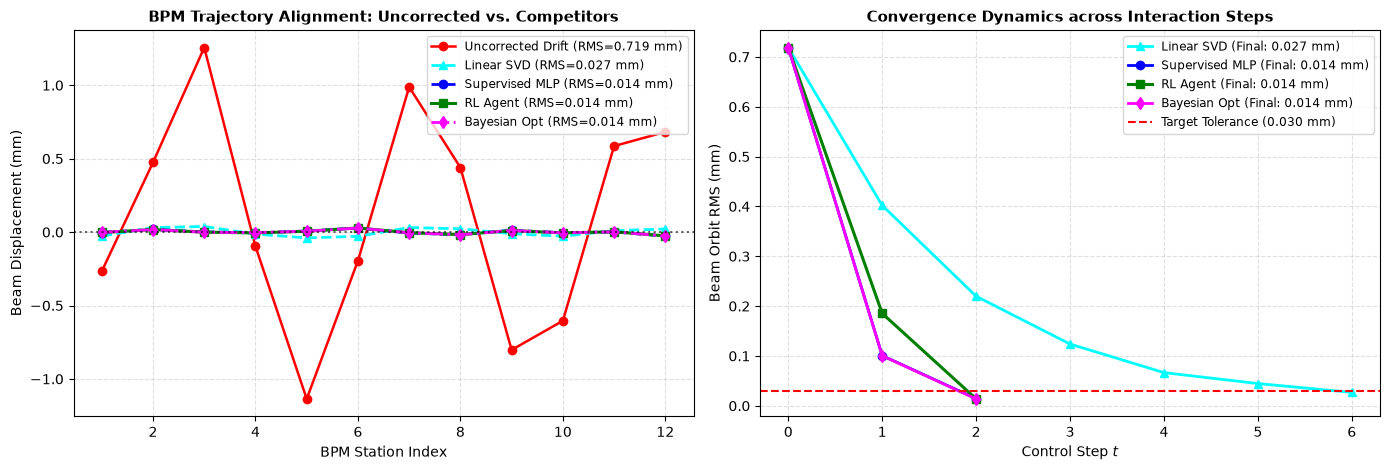

In [7]:
# Step 6: Generate Dual Trajectory Overlay & Dynamic Convergence Curves
# ==============================================================================
# [DO NOT MODIFY - Canonical Diagnostic Visualization]
# ==============================================================================
fig = plot_benchmark_trajectories(
    env,
    controllers={
        "Linear SVD": b0,
        "Supervised MLP": b1,
        "RL Agent": b2,
        "Bayesian Opt": b3
    },
    seed=42,
    save_path="img/benchmark_trajectories.png",
    show=True
)


---
## 7. Final Team Showcase Cell (16:30–17:00)
Run this single summary cell during team presentations to display your official Hackathon submission score!


In [8]:
# Step 7: Final Team Showcase Presentation Summary
# ==============================================================================
# [DO NOT MODIFY - Automated Showcase Scorecard for Presentation]
# ==============================================================================
best_agent_name, best_metrics = max(
    [("Track 3 (Bayesian Optimization)", res_b3),
     ("Track 2 (RL Closed-Loop Agent)", res_b2),
     ("Baseline 1 (Supervised MLP)", res_b1),
     ("Baseline 0 (Linear SVD)", res_b0)],
    key=lambda item: item[1]["score"]
)

print("=" * 68)
print(f"   TEAM: {TEAM_NAME} — OFFICIAL HACKATHON BENCHMARK SUBMISSION")
print("=" * 68)
print(f"  • Best Performing Agent  : {best_agent_name}")
print(f"  • Official Total Score   : {best_metrics['score']:.1f} points")
print(f"  • Alignment Success Rate : {best_metrics['success_rate']:.1f}%")
print(f"  • Mean Steps to Target   : {best_metrics['mean_steps']:.1f} steps")
print(f"  • Mean Residual Orbit RMS: {best_metrics['mean_rms']:.4f} mm")
print(f"  • Mean Corrector Norm    : {best_metrics['mean_norm']:.2f} A")
print(f"  • Mean Policy Latency    : {best_metrics['mean_latency']:.2f} ms")
print("=" * 68)


   TEAM: MA_B8_DeepTwinInversion — OFFICIAL HACKATHON BENCHMARK SUBMISSION
  • Best Performing Agent  : Baseline 1 (Supervised MLP)
  • Official Total Score   : 920.8 points
  • Alignment Success Rate : 100.0%
  • Mean Steps to Target   : 1.5 steps
  • Mean Residual Orbit RMS: 0.0131 mm
  • Mean Corrector Norm    : 0.93 A
  • Mean Policy Latency    : 614.90 ms
